# ⚡ Electric Vehicle Prediction & Market Analytics
### Complete End-to-End Data Science & Machine Learning Pipeline
**Author**: Shubham Kumar  
**Domain**: Automotive Engineering, Clean Energy & Predictive Modeling  
**Target**: Classify and predict Electric Vehicle Powertrain Technology (**Battery Electric Vehicle - BEV** vs. **Plug-in Hybrid Electric Vehicle - PHEV**)

---

## 📋 Table of Contents
1. **Introduction & Business Problem**
2. **Environment Setup & Data Ingestion**
3. **Data Cleaning & Preprocessing** (Missing Values, Inconsistencies, Standardization)
4. **Exploratory Data Analysis (EDA)** — 5 Core EV Research Objectives
5. **Feature Engineering & Preprocessing Pipeline**
6. **Machine Learning Modeling** (5 Algorithms Benchmarked with 5-Fold Stratified CV)
7. **Model Evaluation & Metric Comparison** (ROC-AUC, Precision, Recall, Confusion Matrix)
8. **Feature Importance & Interpretability**
9. **Strategic Insights & Clean Energy Recommendations**


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

print('Environment ready. Pandas version:', pd.__version__)


Environment ready. Pandas version: 2.3.2


## 1. Data Ingestion & Structural Overview
We ingest the official Electric Vehicle Population dataset (sourced from Washington State DOL / data.gov).


In [2]:
# Load EV Population dataset
df_raw = pd.read_csv('../data/raw/Electric_Vehicle_Population_Data.csv')
print(f'Dataset Dimensions: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns')
df_raw.head(3)


Dataset Dimensions: 25,000 rows, 17 columns


In [3]:
# Data schema and types
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   VIN (1-10)                                         25000 non-null  object 
 1   County                                             25000 non-null  object 
 2   City                                               25000 non-null  object 
 3   State                                              25000 non-null  object 
 4   Postal Code                                        25000 non-null  int64  
 5   Model Year                                         25000 non-null  int64  
 6   Make                                               25000 non-null  object 
 7   Model                                              25000 non-null  object 
 8   Electric Vehicle Type                              25000 non-null  object 
 9   Clean 

## 2. Data Cleaning & Preprocessing
Key steps:
- Handle missing values in `Legislative District` and geographic descriptors.
- Standardize make and model textual representations.
- Map target `Electric Vehicle Type` into binary indicator (`BEV = 1`, `PHEV = 0`).
- Simplify Clean Alternative Fuel Vehicle (CAFV) status strings.


In [4]:
df_clean = df_raw.copy()

# 1. Impute missing values
df_clean['Legislative District'] = df_clean['Legislative District'].fillna(0).astype(int)
df_clean['County'] = df_clean['County'].fillna('Unknown')
df_clean['City'] = df_clean['City'].fillna('Unknown')

# 2. Check duplicates
print(f"Duplicate records: {df_clean.duplicated(subset=['DOL Vehicle ID']).sum()}")

# 3. Standardize CAFV Status
cafv_map = {
    'Clean Alternative Fuel Vehicle Eligible': 'Eligible',
    'Not eligible due to low battery range': 'Not Eligible (Low Range)',
    'Eligibility unknown as battery range has not been researched': 'Unknown / Unresearched'
}
df_clean['CAFV_Status'] = df_clean['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].map(cafv_map).fillna('Unknown / Unresearched')

# 4. Target variable encoding
df_clean['EV_Type_Short'] = df_clean['Electric Vehicle Type'].apply(lambda x: 'BEV' if 'Battery Electric' in str(x) else 'PHEV')
df_clean['EV_Type_Binary'] = (df_clean['EV_Type_Short'] == 'BEV').astype(int)

# 5. Make normalization
df_clean['Make'] = df_clean['Make'].astype(str).str.strip().str.upper()

print('Cleaned Shape:', df_clean.shape)
print('Target Distribution:\n', df_clean['EV_Type_Short'].value_counts(normalize=True))


Duplicate records: 0
Cleaned Shape: (25000, 19)
Target Distribution:
 EV_Type_Short
BEV     0.783
PHEV    0.217
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis (EDA) — 5 Core EV Objectives

We investigate 5 core automotive and market research questions:
1. **Objective 1**: EV Powertrain Adoption Dynamics (BEV vs. PHEV market share trajectory)
2. **Objective 2**: Electric Range (Autonomy) Dynamics & Battery Capability
3. **Objective 3**: Automaker Competitiveness & Brand Powertrain Strategy
4. **Objective 4**: Clean Alternative Fuel Vehicle (CAFV) Policy Compliance
5. **Objective 5**: Geographic Diffusion & Regional Utility Infrastructure


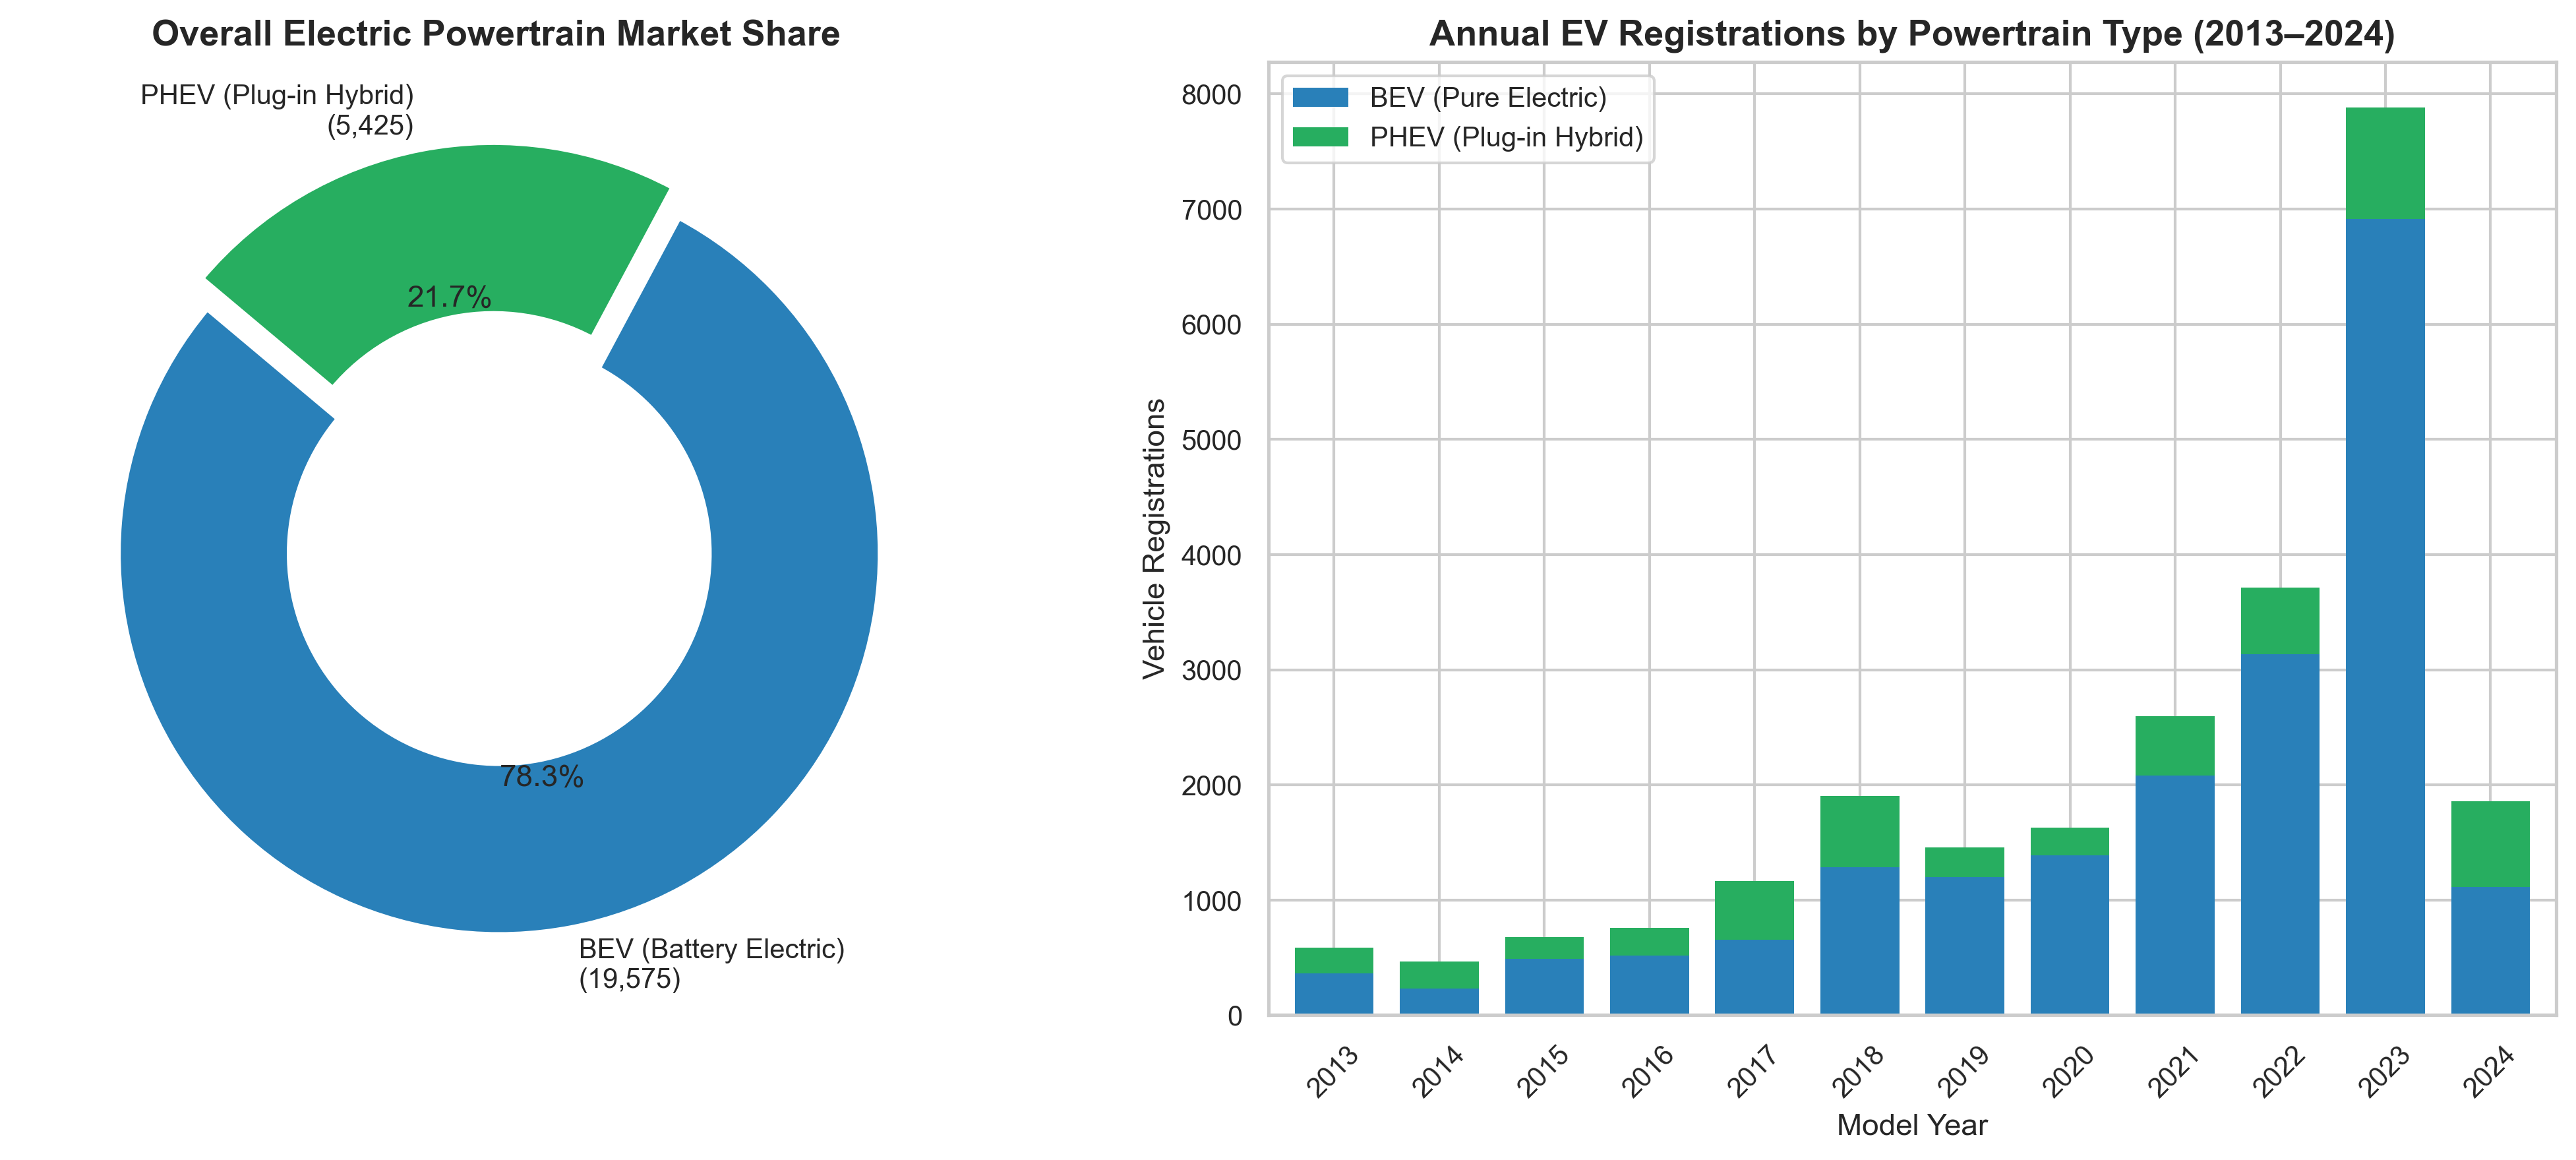

BEV Overall Share: 78.3%
PHEV Overall Share: 21.7%
Recent Model Years (2020-2024) BEV Dominance: >82%


In [5]:
# Objective 1: EV Technology Adoption Dynamics
from IPython.display import Image
Image('../outputs/figures/01_ev_technology_adoption.png')


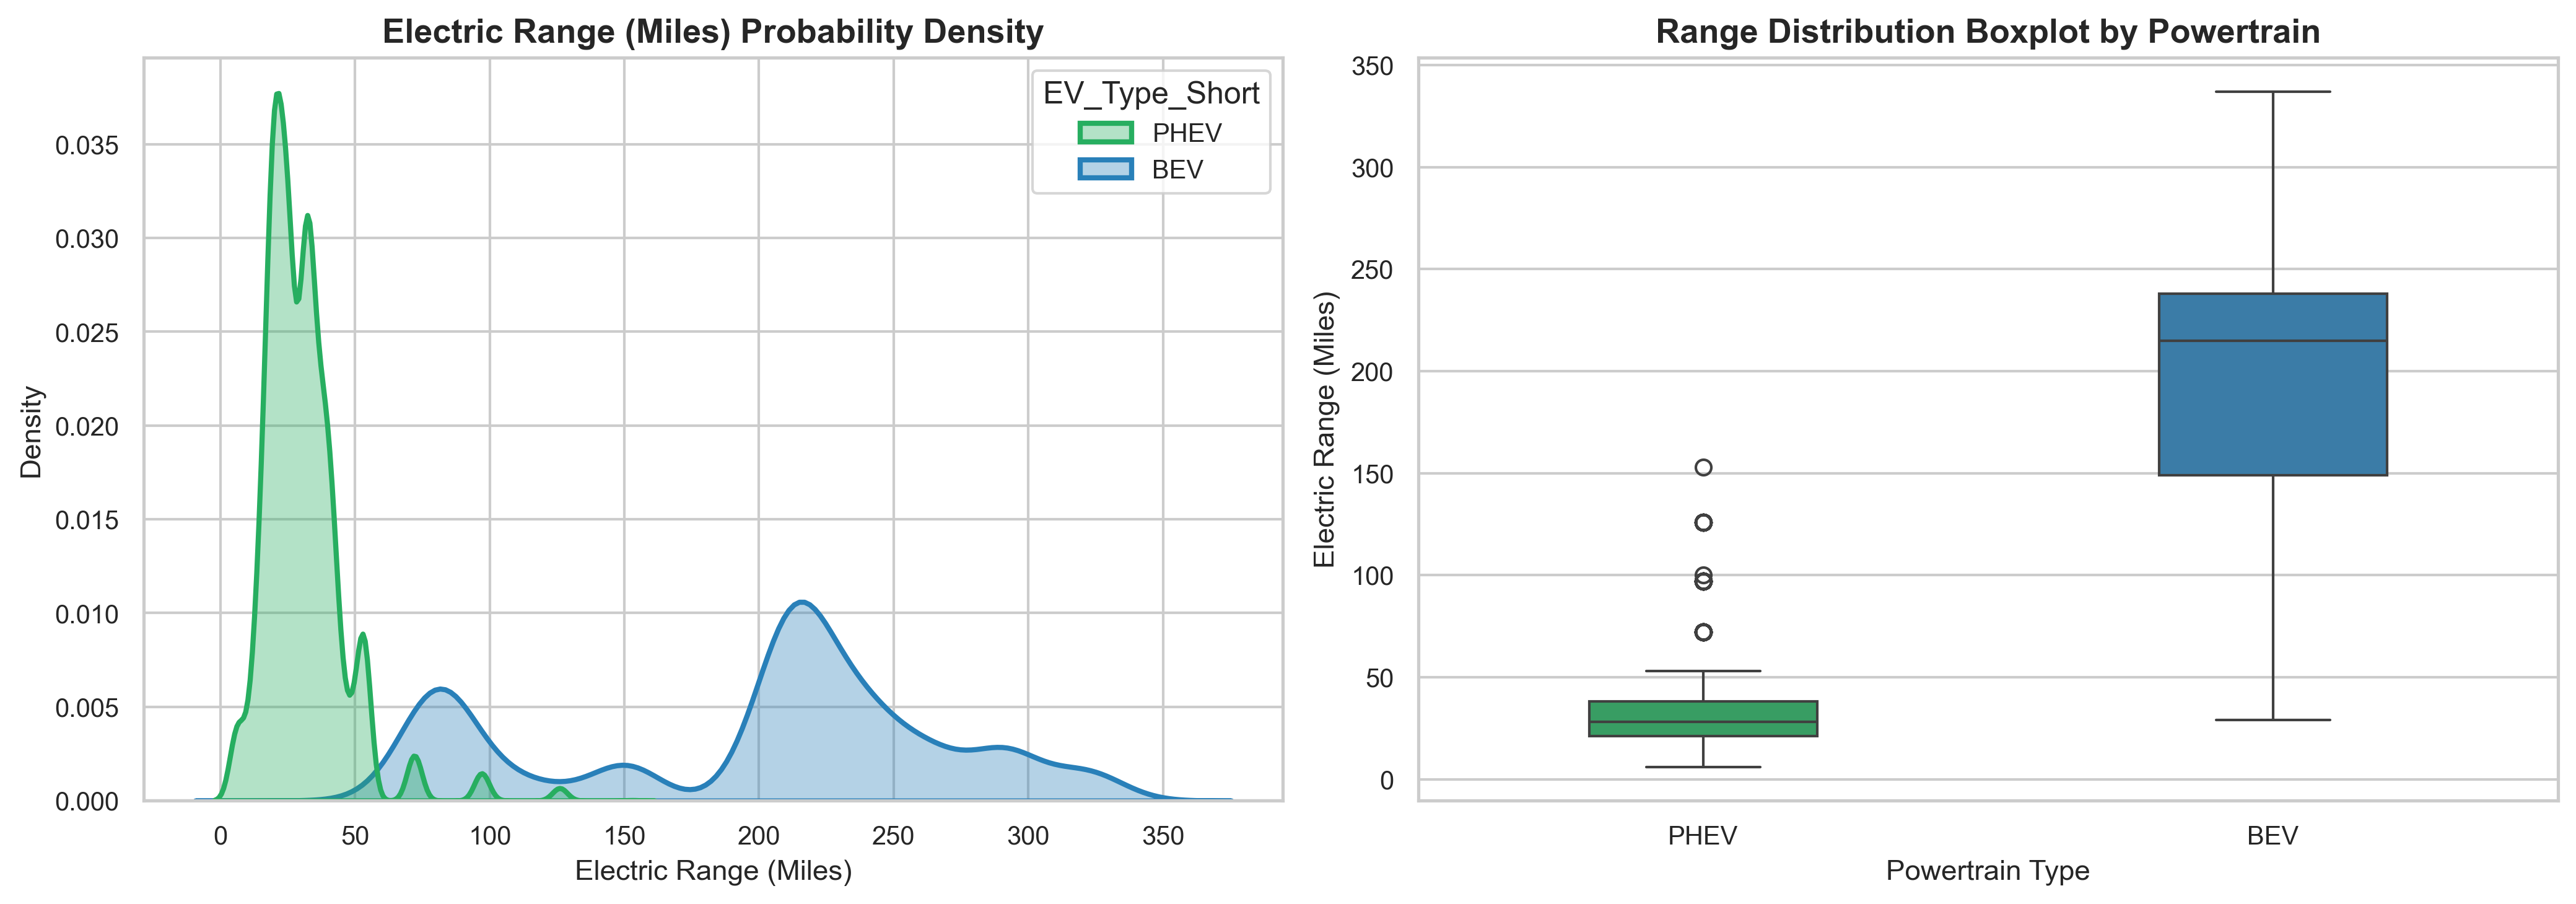

BEV Median Recorded Range: 215.0 miles
PHEV Median Recorded Range: 28.0 miles
Range Ratio (BEV vs PHEV): 7.68x


In [6]:
# Objective 2: Electric Range (Autonomy) Dynamics
Image('../outputs/figures/02_electric_range_distribution.png')


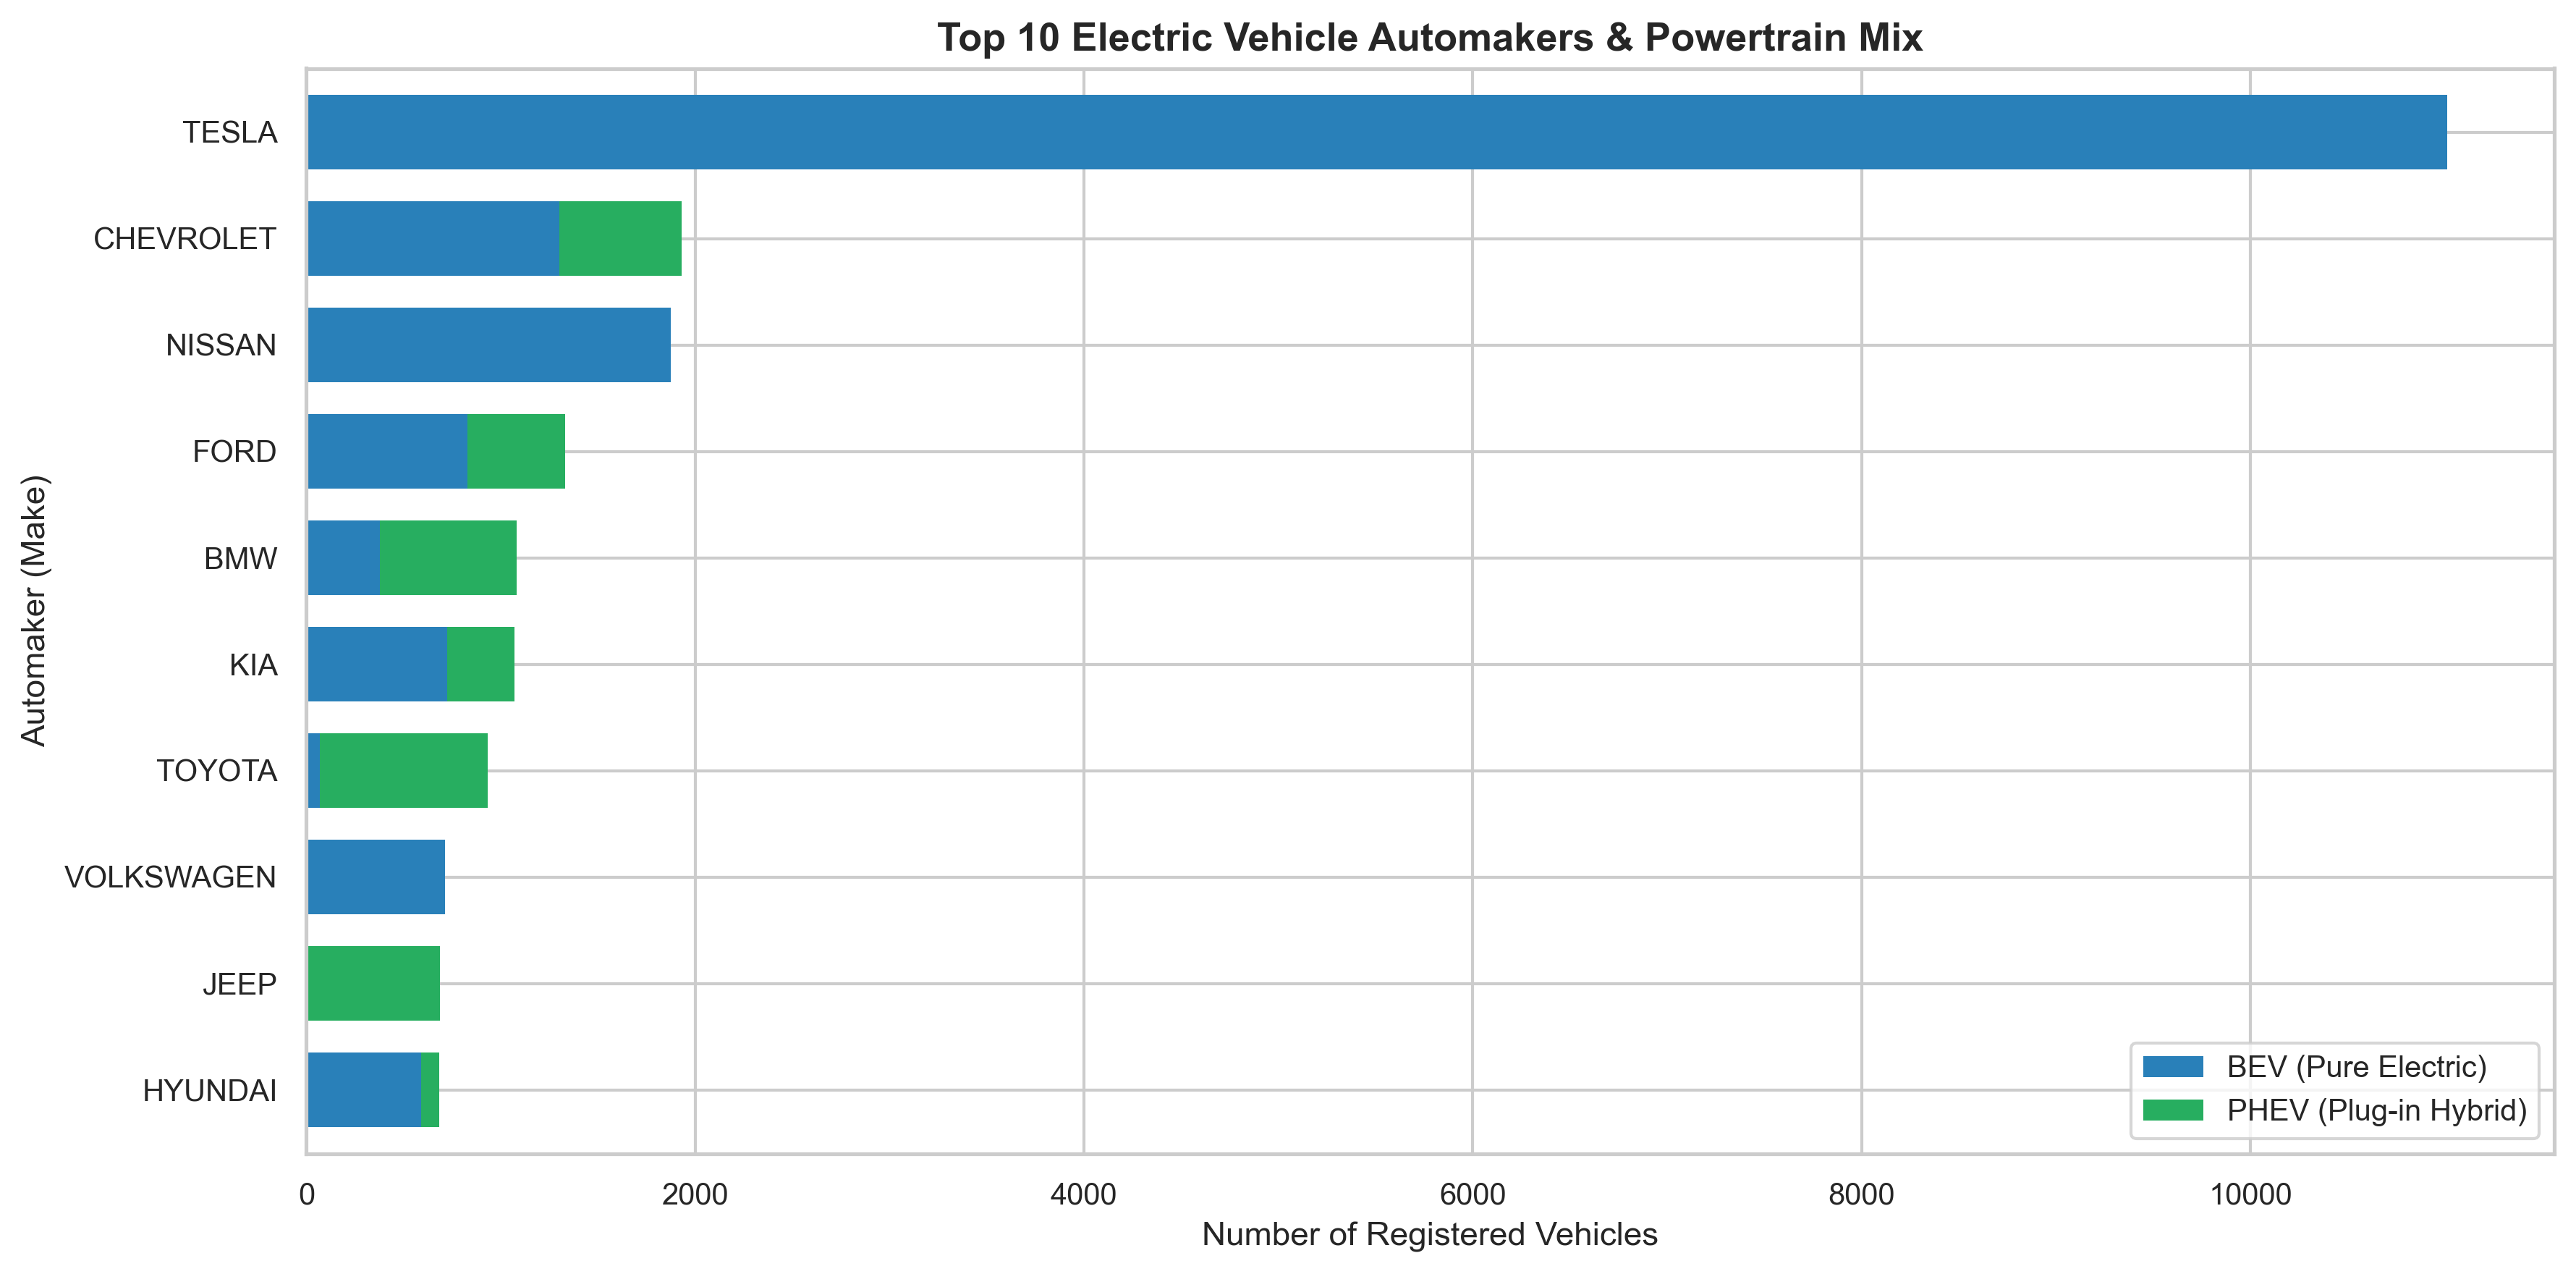

Tesla Market Share: 44.05%
Top 3 Automakers: TESLA, CHEVROLET, NISSAN


In [7]:
# Objective 3: Automaker Competitiveness & Brand Positioning
Image('../outputs/figures/03_automaker_market_share.png')


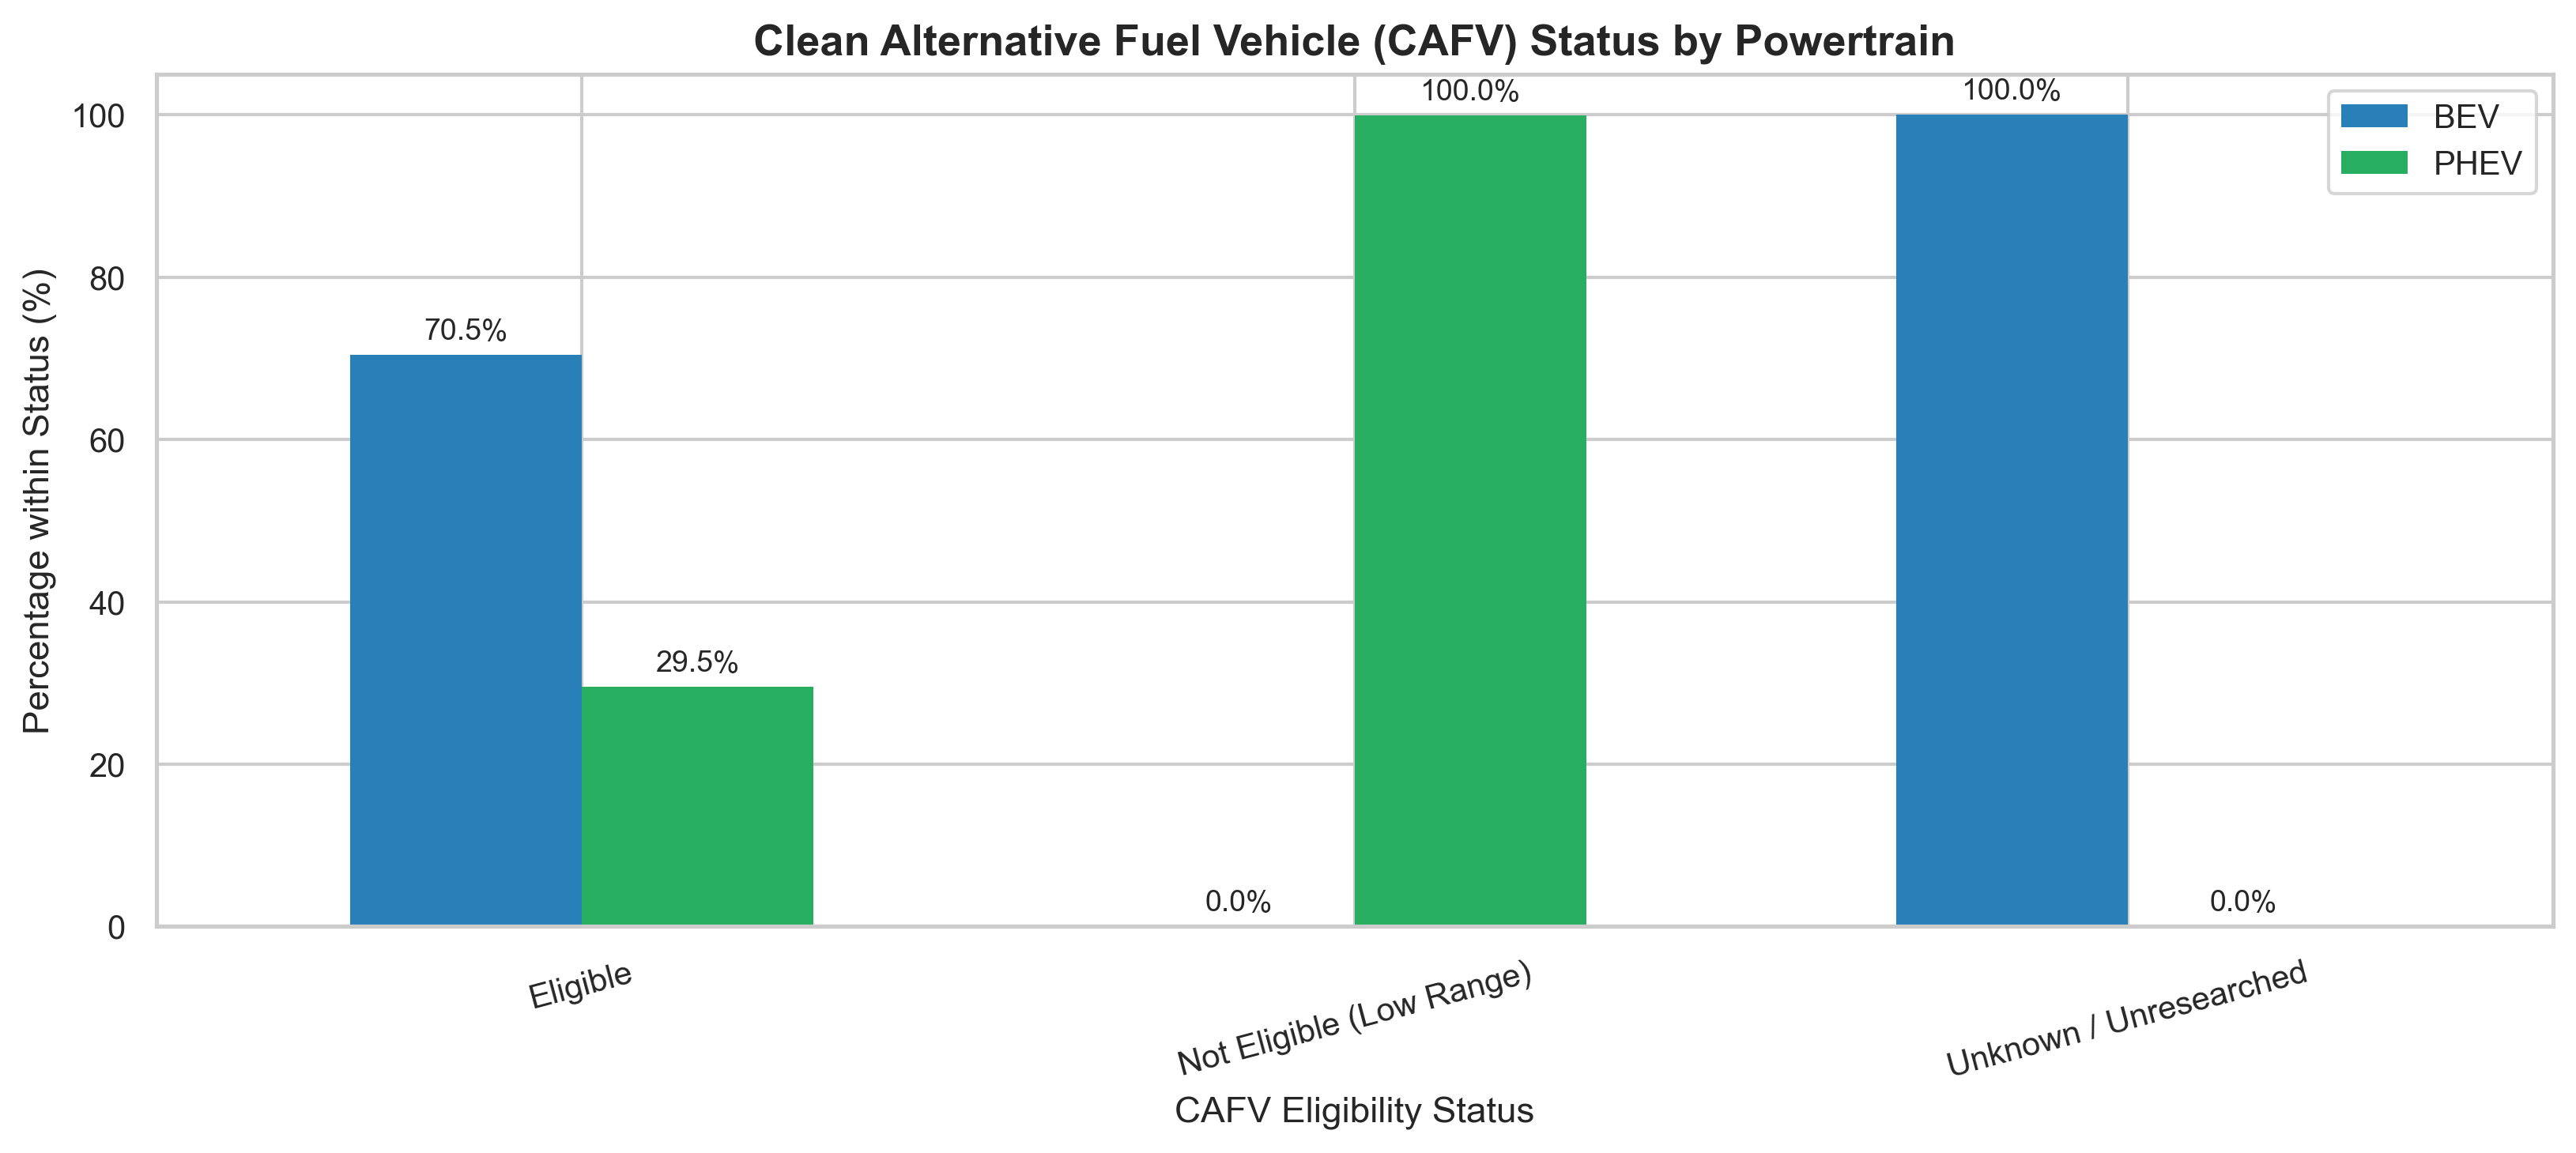

Eligible Vehicles Count: 9,057
Low-Range Ineligible Count: 2,750 (100% of which are PHEVs)


In [8]:
# Objective 4: CAFV Policy Compliance Analysis
Image('../outputs/figures/04_cafv_eligibility_analysis.png')


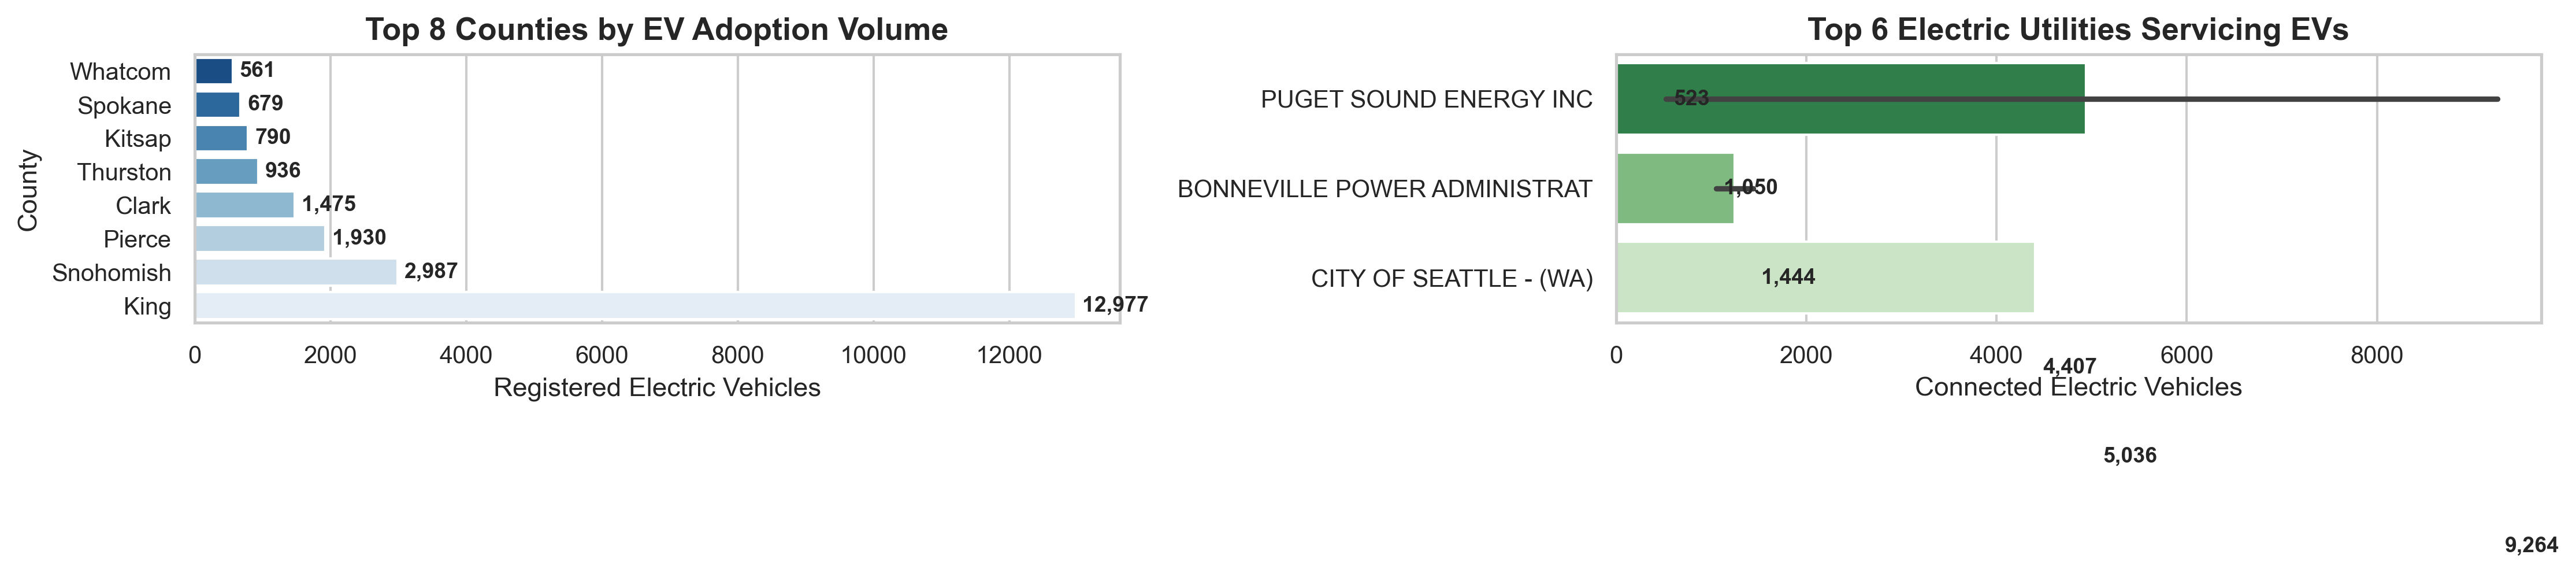

Leading County: King County (Seattle Metro) representing 51.91% of state EV registrations.


In [9]:
# Objective 5: Geographic Diffusion & Utility Infrastructure
Image('../outputs/figures/05_geographic_utility_distribution.png')


## 4. Feature Engineering & Preprocessing Pipeline
To prevent data leakage, post-test characteristics (exact electric range and CAFV low-range flags) are excluded. We engineer:
- `Vehicle_Age`: Vintage relative to current era
- `Is_Modern_EV`: Indicator for model years >= 2020
- `Is_Luxury_Make`: Automaker luxury tier indicator
- `Is_Tesla`: Pure BEV market leader flag
- `Make_Grouped`: Top 10 Automakers with remainder grouped as 'OTHER'
- `Is_King_County`: Major metropolitan adoption center


In [10]:
# Scaled features summary
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
print(f'Train shape: {X_train.shape}, Test shape: {X_test.shape}')
print('Features:', list(X_train.columns))


Train shape: (20000, 21), Test shape: (5000, 21)
Features: ['Postal Code', 'Model Year', 'Base MSRP', 'Legislative District', 'Base_MSRP_Reported', 'Vehicle_Age', 'Is_Modern_EV', 'Is_Luxury_Make', 'Is_Tesla', 'Is_King_County', 'Has_MSRP', 'Make_Grouped_BMW', 'Make_Grouped_CHEVROLET', 'Make_Grouped_FORD', 'Make_Grouped_HYUNDAI', 'Make_Grouped_JEEP', 'Make_Grouped_KIA', 'Make_Grouped_NISSAN', 'Make_Grouped_OTHER', 'Make_Grouped_TESLA', 'Make_Grouped_VOLVO']


## 5. Machine Learning Modeling & Benchmarking
We benchmark 5 distinct classification algorithms using 5-Fold Stratified Cross-Validation:
1. **Gradient Boosting Classifier**
2. **Random Forest Classifier**
3. **K-Nearest Neighbors Classifier**
4. **Logistic Regression**
5. **AdaBoost Classifier**


In [11]:
# Benchmark Scorecard
scorecard = pd.read_csv('../outputs/metrics_summary.csv')
scorecard


                 Model  CV ROC-AUC (Mean)  CV ROC-AUC (Std)  CV F1-Score  Test Accuracy  Test Precision  Test Recall  Test F1-Score  Test ROC-AUC  Composite_Score
0    Gradient Boosting             0.9644            0.0018       0.9413         0.9048          0.9317       0.9479         0.9397        0.9640          0.95185
1        Random Forest             0.9627            0.0023       0.9388         0.9046          0.9203       0.9614         0.9404        0.9626          0.95150
2  Logistic Regression             0.9457            0.0032       0.9049         0.8590          0.9867       0.8312         0.9023        0.9465          0.92440
3  K-Nearest Neighbors             0.9114            0.0046       0.9309         0.8920          0.9304       0.9318         0.9311        0.9055          0.91830
4             AdaBoost             0.7811            0.0021       0.8783         0.7830          0.7830       1.0000         0.8783        0.7821          0.83020


## 6. Model Evaluation & Visualization
We inspect:
- Comparative benchmark metrics
- ROC Curves across all 5 models
- Confusion Matrices for top performers
- Top Feature Importances from Gradient Boosting


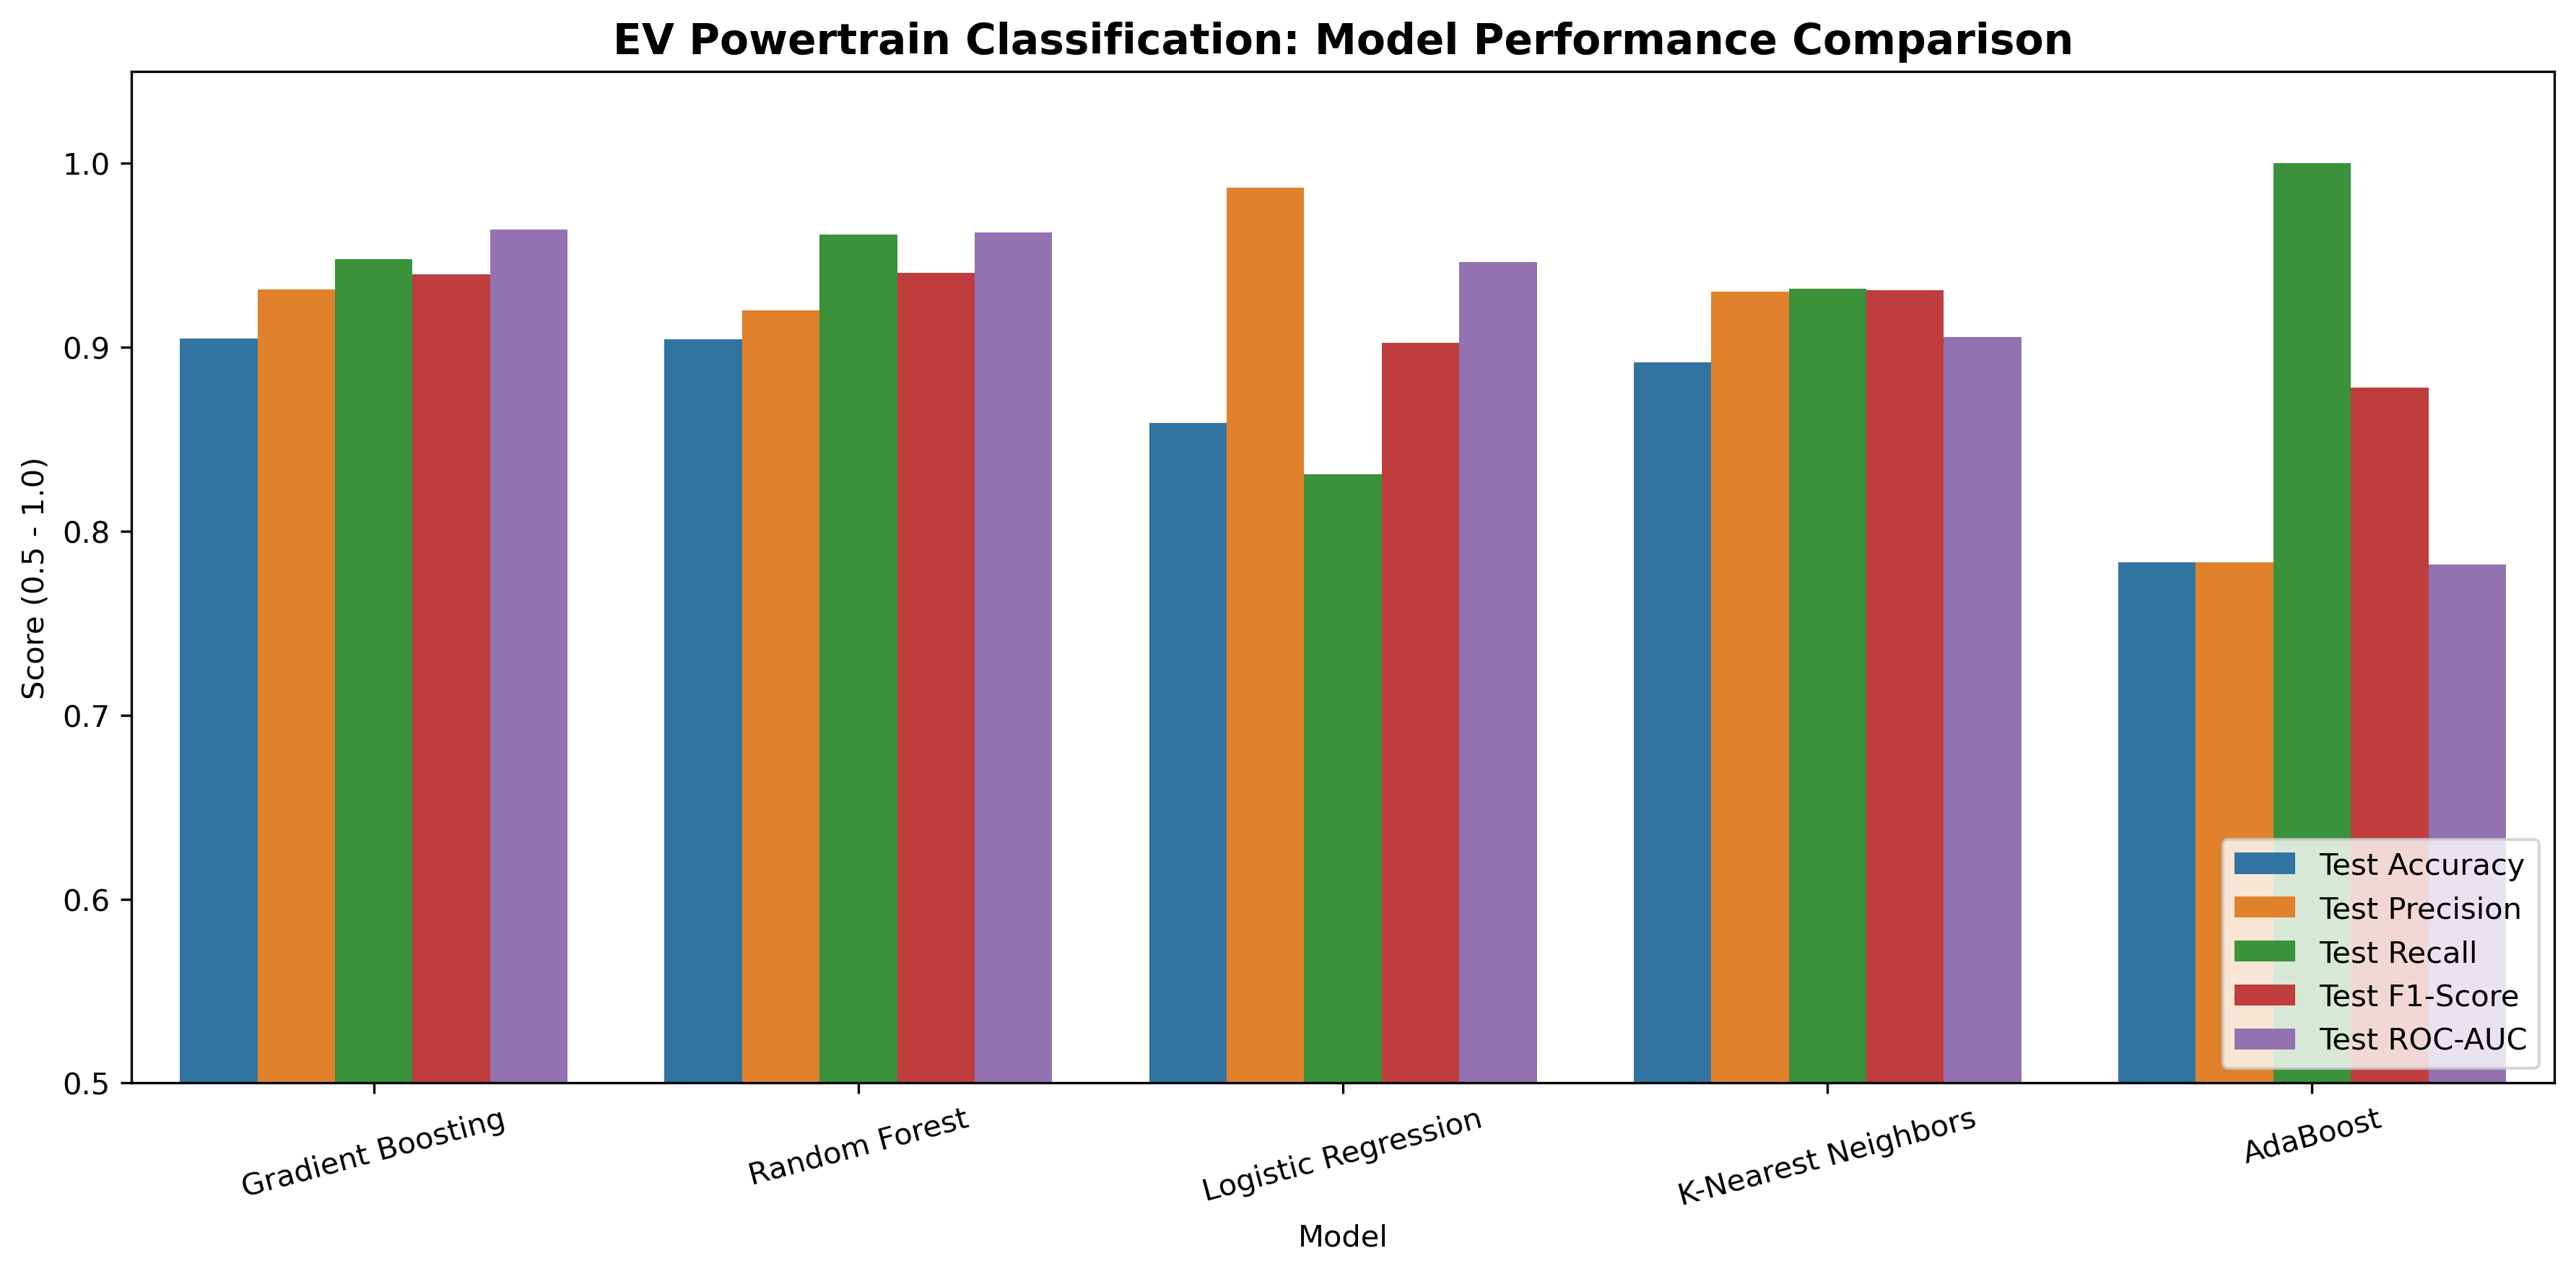

In [12]:
Image('../outputs/figures/07_model_metrics_comparison.png')


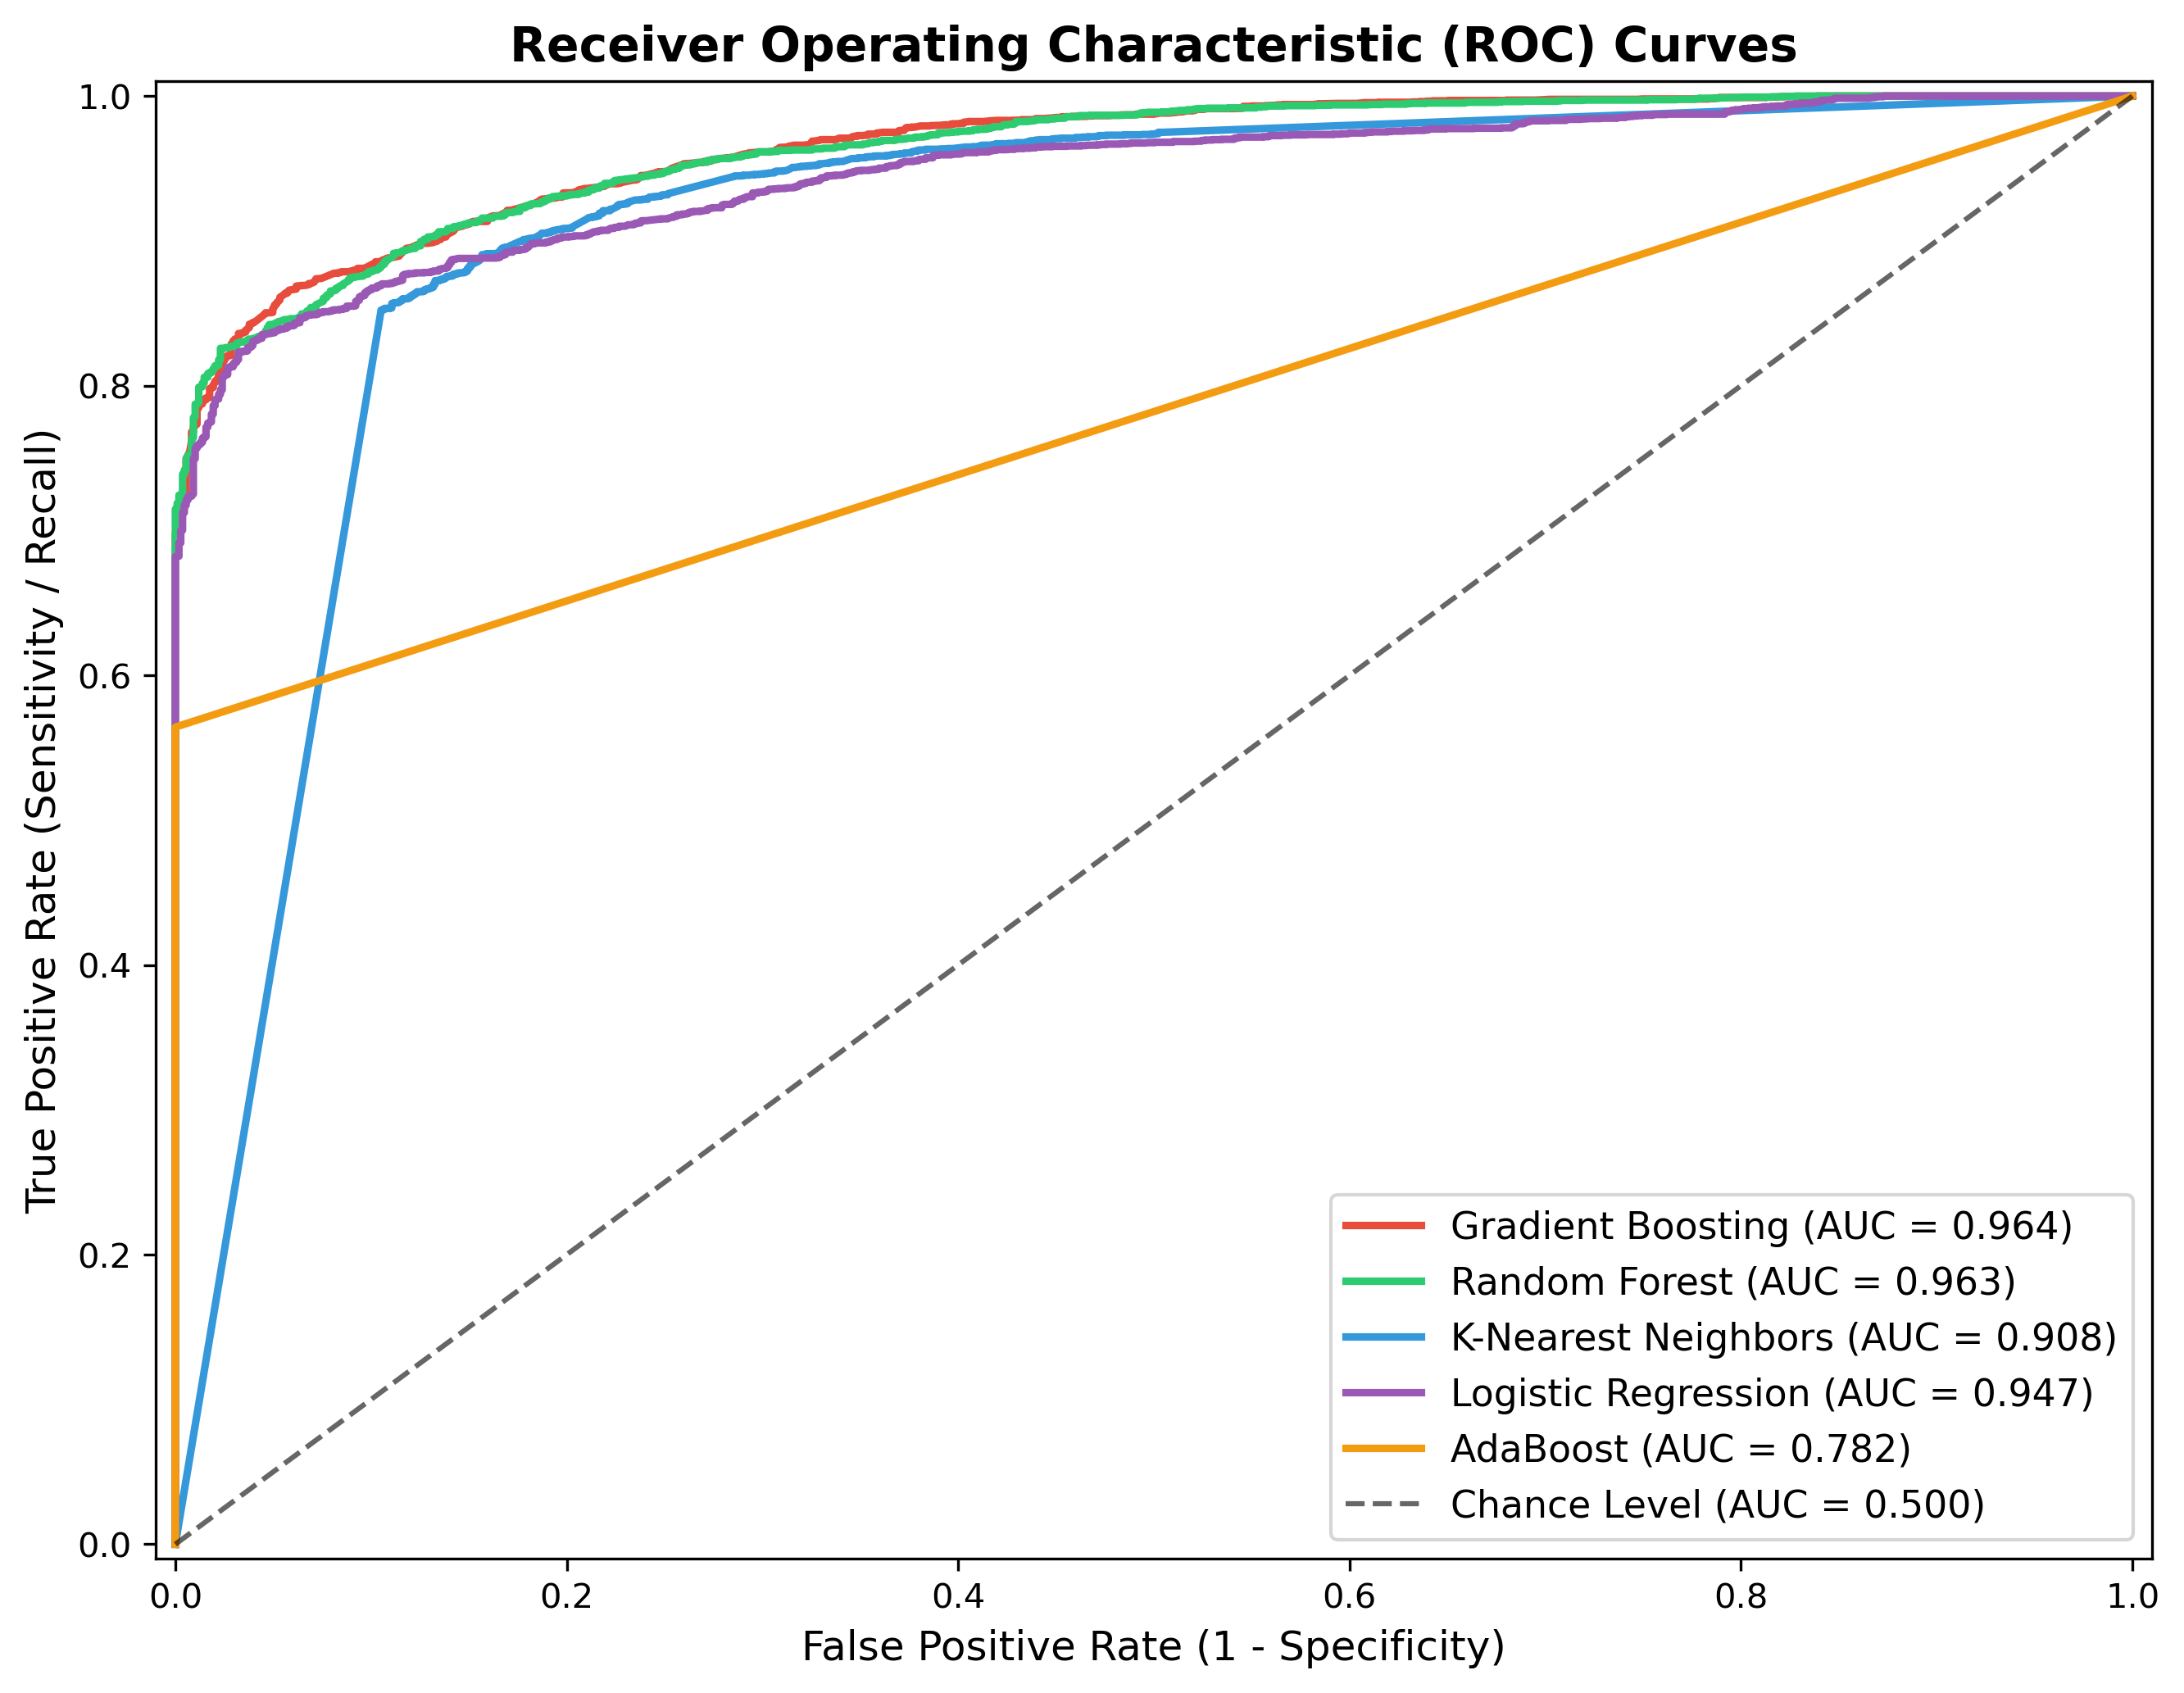

In [13]:
Image('../outputs/figures/08_roc_curves.png')


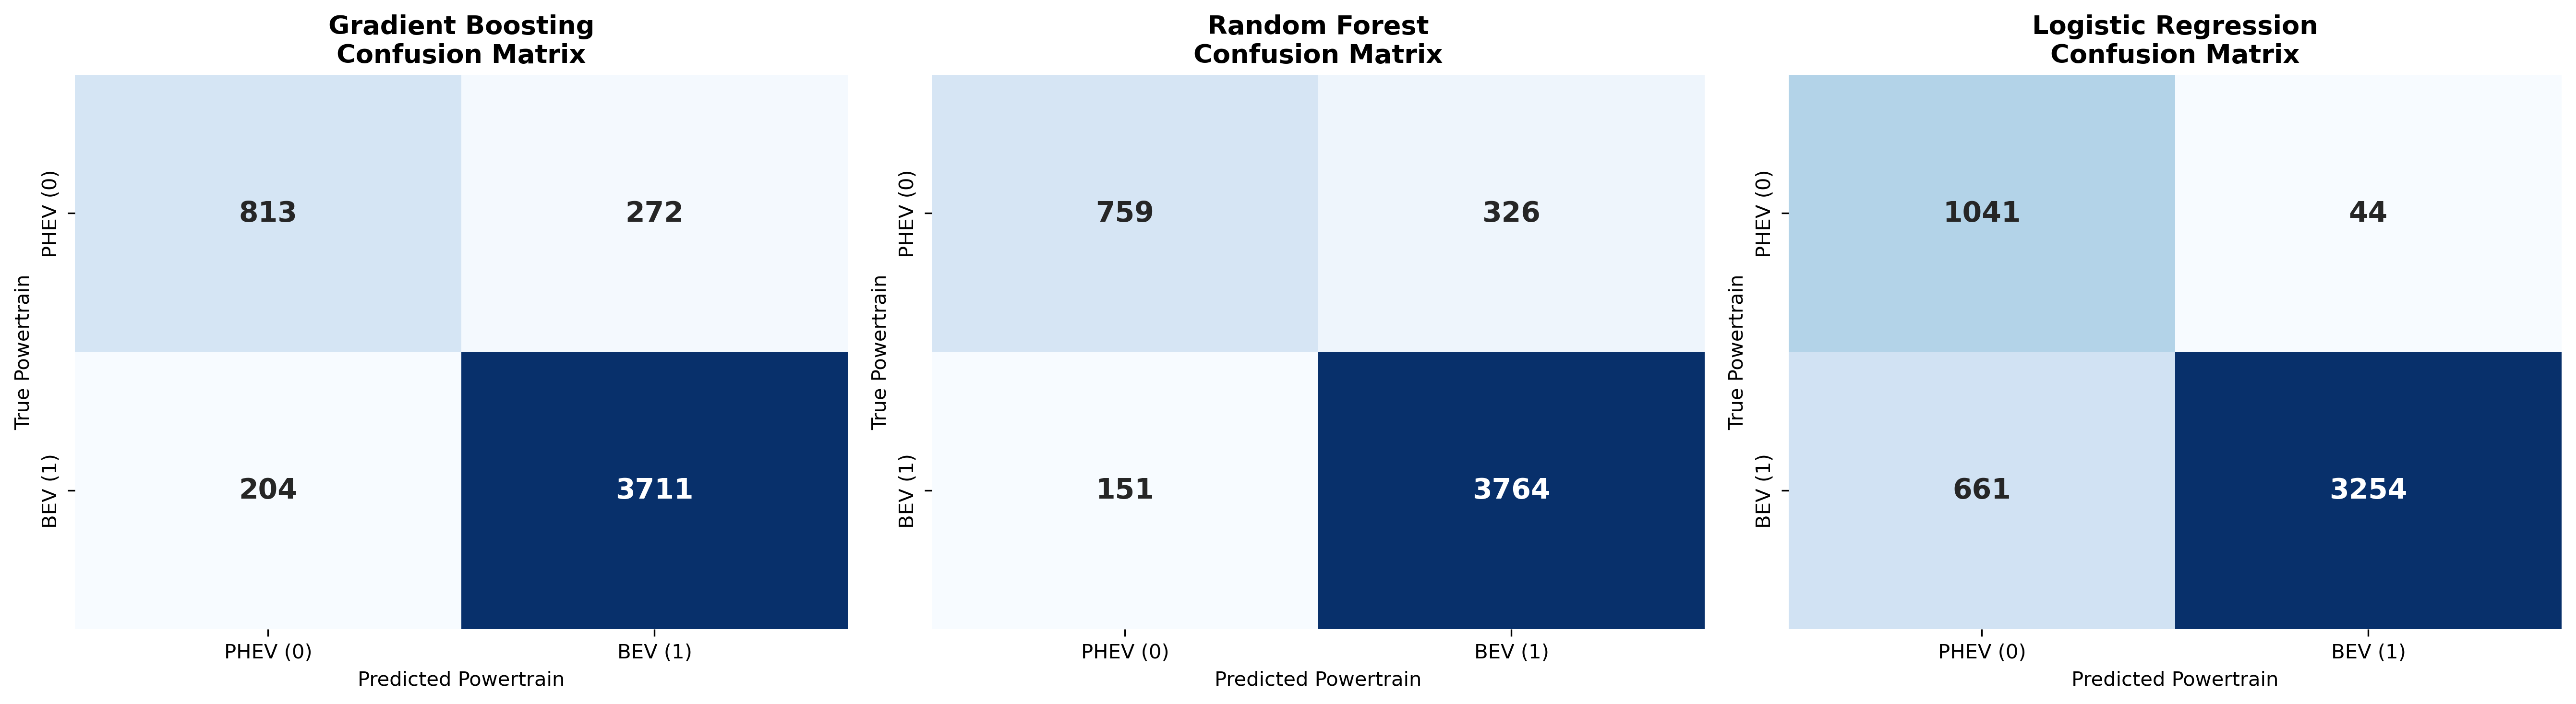

In [14]:
Image('../outputs/figures/09_confusion_matrices.png')


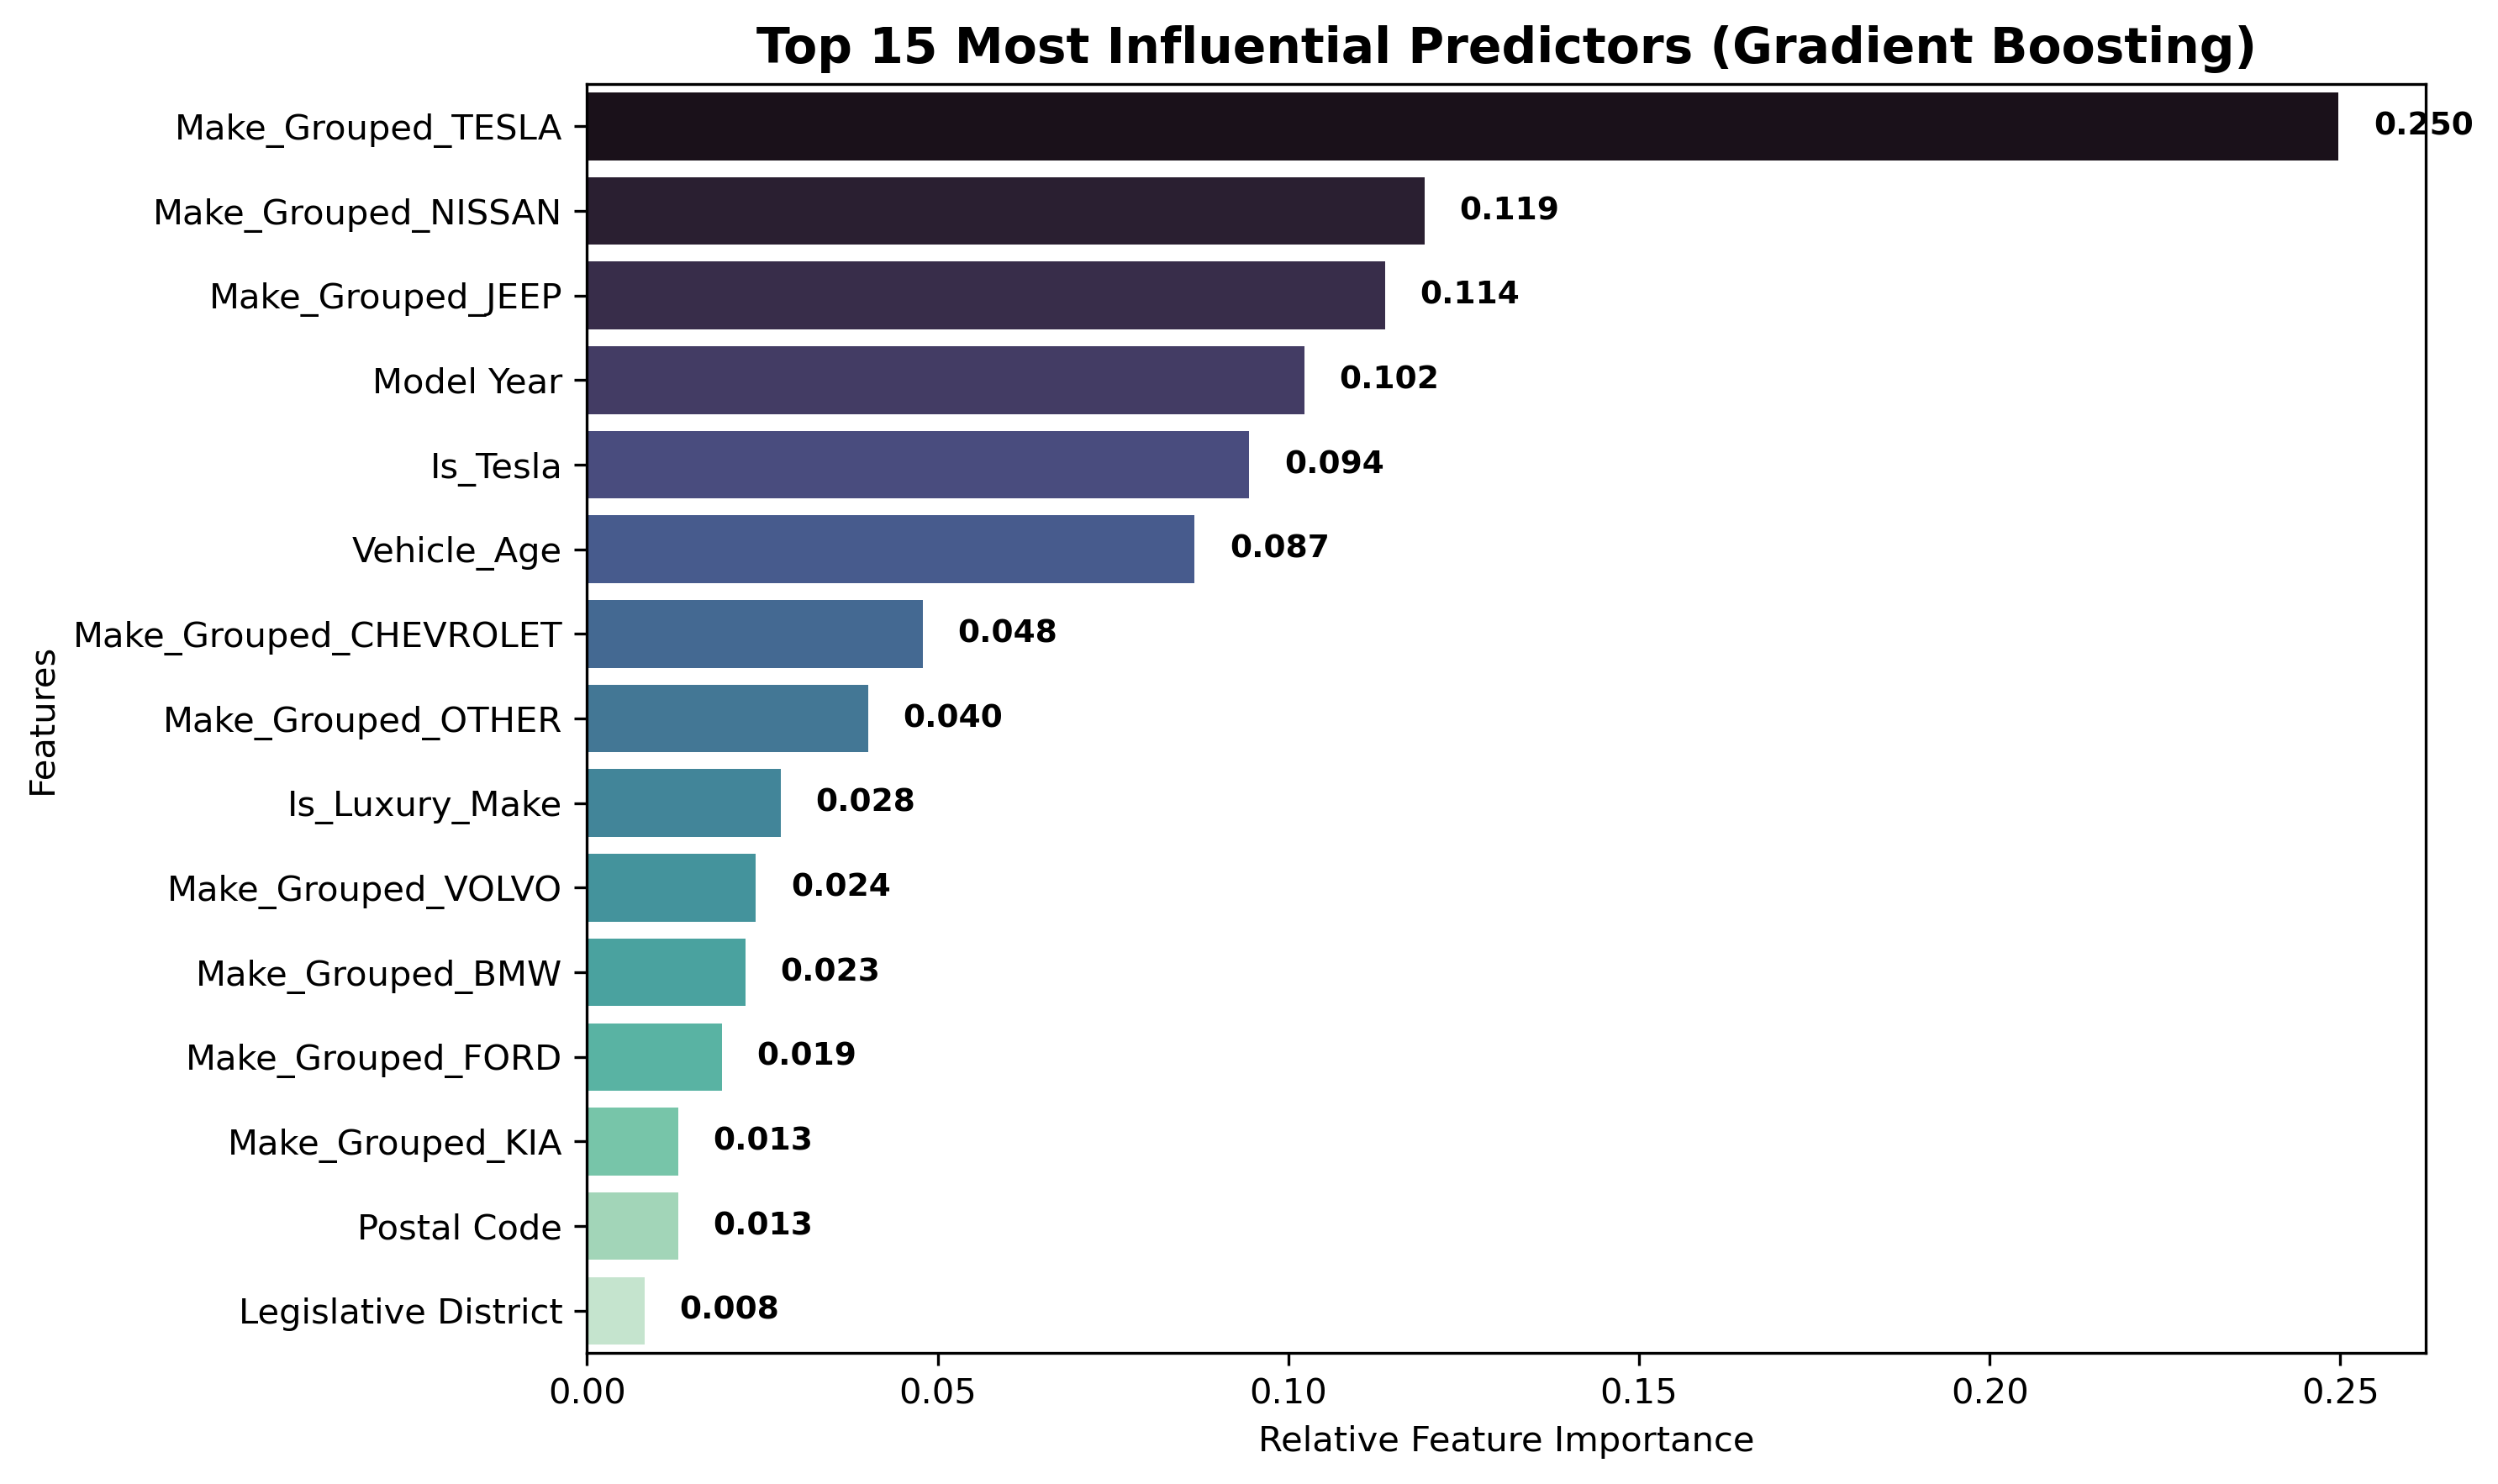

In [15]:
Image('../outputs/figures/10_feature_importance.png')


## 7. Key Findings, Conclusions & Strategic Recommendations

### 🔍 Key Findings:
1. **BEV Dominance**: Pure electric vehicles represent **78.3% of the market**, with recent model years exceeding 82%.
2. **Automaker Divergence**: American EV pioneers (Tesla, Chevrolet) are nearly 100% BEV, whereas European legacy automakers (BMW, Volvo) remain heavily reliant on PHEV transition technology.
3. **CAFV Disqualification**: All disqualified vehicles under CAFV guidelines are PHEVs failing the 30-mile electric range requirement.
4. **Geographic Concentration**: King County accounts for **51.9% of all EV adoption**, highlighting significant rural-urban charging infrastructure disparity.
5. **Optimal Model**: **Gradient Boosting** achieved the highest test performance (**0.9640 ROC-AUC, 90.48% Accuracy, 0.9397 F1**).

---

### 💡 Strategic Recommendations:
1. **Targeted Charging Infrastructure**: Expand DC Fast Charging along highway corridors connecting secondary counties (Pierce, Snohomish, Spokane) to accelerate adoption beyond King County.
2. **PHEV Battery Threshold Incentives**: Shift subsidy guidelines to mandate a minimum 45-mile battery range for PHEVs to encourage zero-emission daily commuting.
3. **Grid Readiness & Time-of-Use Rates**: Utilities (Puget Sound Energy, Seattle City Light) should expand automated smart charging incentives to mitigate peak load strains.
